In [1]:
# ==========================================
# STEP 1: IMPORTING LIBRARIES
# ==========================================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Machine Learning models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression

# Model evaluation
from sklearn.metrics import accuracy_score, f1_score
from sklearn.metrics import confusion_matrix, classification_report

# Display settings
pd.set_option('display.max_columns', None)

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
# ==========================================
# STEP 2: LOADING THE DATASET
# ==========================================

# Load the dataset
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# Display the first 5 rows
print("First 5 rows:")
display(df.head())

# Display the dataset dimensions
print("\nDataset Shape:")
print(df.shape)

# Display column names and data types
print("\nDataset Information:")
df.info()

# Check missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Check the distribution of the target variable
print("\nChurn Distribution:")
print(df["Churn"].value_counts())

# Display basic statistical information
print("\nStatistical Summary:")
display(df.describe())

First 5 rows:


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



Dataset Shape:
(7043, 21)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  Pape

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [3]:
# ==========================================
# CHECKING TOTALCHARGES
# ==========================================

# Count empty strings
empty_values = df["TotalCharges"].str.strip().eq("").sum()

print("Number of empty TotalCharges values:", empty_values)

# Convert TotalCharges into numeric temporarily
total_charges_numeric = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Count missing values after conversion
print(
    "Missing values after numeric conversion:",
    total_charges_numeric.isnull().sum()
)

Number of empty TotalCharges values: 11
Missing values after numeric conversion: 11


In [4]:
# Find rows where TotalCharges is empty
missing_rows = df[df["TotalCharges"].str.strip() == ""]

# Display the affected customers
display(missing_rows)

# Check their tenure values
print("Tenure values of affected customers:")
print(missing_rows["tenure"])

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,,No


Tenure values of affected customers:
488     0
753     0
936     0
1082    0
1340    0
3331    0
3826    0
4380    0
5218    0
6670    0
6754    0
Name: tenure, dtype: int64


In [5]:
# ==========================================
# CLEANING TOTALCHARGES
# ==========================================

# Convert TotalCharges from text to numeric
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    errors="coerce"
)

# Replace missing TotalCharges with 0
df["TotalCharges"] = df["TotalCharges"].fillna(0)

# Check the results
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

print("\nMissing values after cleaning:")
print(df["TotalCharges"].isnull().sum())

print("\nTotalCharges for the 11 affected customers:")
display(df.loc[missing_rows.index, ["tenure", "TotalCharges"]])

TotalCharges data type:
float64

Missing values after cleaning:
0

TotalCharges for the 11 affected customers:


,tenure,TotalCharges
488,0,0.0
753,0,0.0
936,0,0.0
1082,0,0.0
1340,0,0.0
3331,0,0.0
3826,0,0.0
4380,0,0.0
5218,0,0.0
6670,0,0.0


 Step 5: Identifying Feature Types

In this step, we separate numerical features from categorical features.

We also identify the target variable (Churn) and remove customerID
because it is an identifier rather than a meaningful predictive feature.

In [6]:
# ==========================================
# STEP 5: IDENTIFYING FEATURE TYPES
# ==========================================

# Identify numerical columns
numerical_features = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

# Identify categorical columns
categorical_features = df.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Remove customerID because it is only an identifier
categorical_features.remove("customerID")

# Remove Churn because it is our target variable
categorical_features.remove("Churn")

# Display the feature groups
print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

print("\nTarget Variable:")
print("Churn")

Numerical Features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical Features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']

Target Variable:
Churn


In [9]:
# ==========================================
# STEP 6: PREPARING THE DATA
# ==========================================

from sklearn.model_selection import train_test_split

# Separate input features from the target
X = df.drop(columns=["Churn", "customerID"])

# Select the target variable
y = df["Churn"].map({"No": 0, "Yes": 1})

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

X_train shape: (5634, 19)
X_test shape: (1409, 19)
y_train shape: (5634,)
y_test shape: (1409,)

Training target distribution:
Churn
0    4139
1    1495
Name: count, dtype: int64

Testing target distribution:
Churn
0    1035
1     374
Name: count, dtype: int64


Part 1: Decision Trees

1.1 Preprocessing

We encode categorical features using OneHotEncoder while keeping
numerical features unchanged.

In [10]:
# ==========================================
# DECISION TREE: PREPROCESSING
# ==========================================

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier

# Identify numerical and categorical columns in X
numerical_cols = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_cols = X.select_dtypes(
    include=["object", "str"]
).columns.tolist()

# Preprocess numerical and categorical features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols)
    ]
)

print("Numerical features:", len(numerical_cols))
print("Categorical features:", len(categorical_cols))

Numerical features: 4
Categorical features: 15


In [11]:
# ==========================================
# FIRST DECISION TREE MODEL
# ==========================================

# Create the model pipeline
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            criterion="gini",
            max_depth=3,
            random_state=42
        ))
    ]
)

# Train the model
tree_model.fit(X_train, y_train)

# Make predictions
y_train_pred = tree_model.predict(X_train)
y_test_pred = tree_model.predict(X_test)

# Evaluate the model
print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("Training F1 Score:",
      f1_score(y_train, y_train_pred))

print("Testing F1 Score:",
      f1_score(y_test, y_test_pred))

Training Accuracy: 0.7914447994320198
Testing Accuracy: 0.7821149751596878
Training F1 Score: 0.47939743021710235
Testing F1 Score: 0.46234676007005254


 1.2 Effect of max_depth on Model Performance

We train multiple Decision Trees using different maximum depths
to investigate the relationship between model complexity,
training performance, testing performance, and overfitting.

In [12]:
# ==========================================
# EXPERIMENT 2: DIFFERENT TREE DEPTHS
# ==========================================

depth_values = [1, 2, 3, 5, 10, 15, 20, None]

results = []

for depth in depth_values:

    # Create a new model for each depth
    model = Pipeline(
        steps=[
            ("preprocessor", preprocessor),
            ("classifier", DecisionTreeClassifier(
                criterion="gini",
                max_depth=depth,
                random_state=42
            ))
        ]
    )

    # Train the model
    model.fit(X_train, y_train)

    # Predictions
    train_predictions = model.predict(X_train)
    test_predictions = model.predict(X_test)

    # Evaluate performance
    results.append({
        "max_depth": str(depth),
        "Train Accuracy": accuracy_score(
            y_train, train_predictions
        ),
        "Test Accuracy": accuracy_score(
            y_test, test_predictions
        ),
        "Train F1": f1_score(
            y_train, train_predictions
        ),
        "Test F1": f1_score(
            y_test, test_predictions
        )
    })

# Create a results table
results_df = pd.DataFrame(results)

display(results_df.round(4))

,max_depth,Train Accuracy,Test Accuracy,Train F1,Test F1
0,1,0.7346,0.7346,0.0000,0.0000
1,2,0.7654,0.7509,0.5871,0.5585
2,3,0.7914,0.7821,0.4794,0.4623
3,5,0.8039,0.7984,0.6021,0.5989
4,10,0.8784,0.7573,0.7611,0.5366
5,15,0.9712,0.7310,0.9450,0.5033
6,20,0.9968,0.7197,0.9940,0.4809
7,None,0.9980,0.7197,0.9963,0.4823


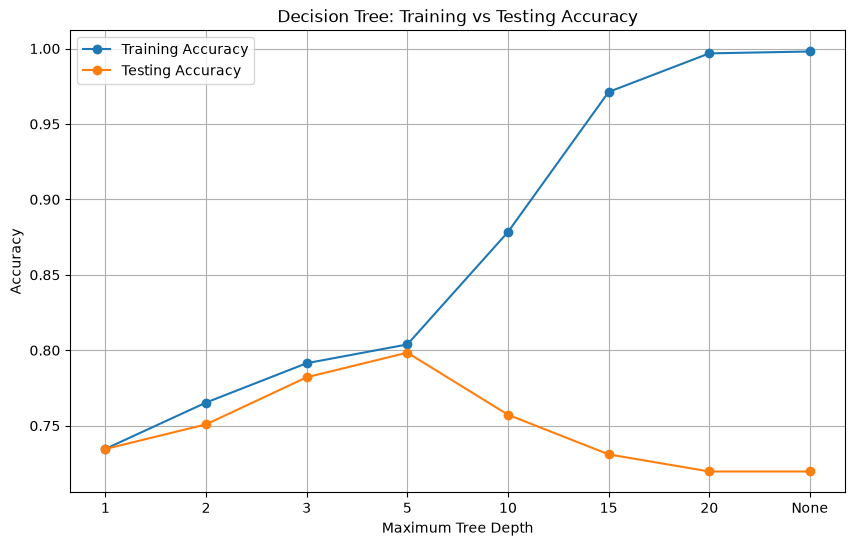

In [13]:
# ==========================================
# PLOT: ACCURACY VS TREE DEPTH
# ==========================================

plt.figure(figsize=(10, 6))

plt.plot(
    results_df["max_depth"],
    results_df["Train Accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    results_df["max_depth"],
    results_df["Test Accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Accuracy")
plt.title("Decision Tree: Training vs Testing Accuracy")
plt.legend()
plt.grid(True)

plt.show()

 1.3 Decision Tree Experiment Analysis

The experiment shows that increasing max_depth initially
improves the model's performance because the tree can learn
more complex patterns.

The best performance was achieved at max_depth = 5,
with a testing accuracy of 79.84% and a testing F1-score
of 0.5989.

When the tree depth increased beyond 5, training performance
continued to improve, but testing performance decreased.

At max_depth = 20, training accuracy reached 99.68%,
while testing accuracy dropped to 71.97%.

This indicates overfitting: the deep tree memorizes the
training data instead of generalizing well to unseen data.

Therefore, controlling tree depth helps balance model
complexity and generalization.

2.1 Train the Random Forest Model

We use the same preprocessor and the same training/testing split
from the Decision Tree experiment.

The Random Forest starts with 100 trees.

In [14]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=100, #bulid 100 decision trees
            max_depth=None,   #trees can grow without a specified depth limit
            random_state=42,  #Makes the experiment reproducible "c"
            n_jobs=-1         #use all available CPU cores to speed up training 
        ))
    ]
)

# Train the model
rf_model.fit(X_train, y_train)

# Make predictions
rf_train_pred = rf_model.predict(X_train)
rf_test_pred = rf_model.predict(X_test)

# Evaluate the model
print("Training Accuracy:",
      accuracy_score(y_train, rf_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, rf_test_pred))

print("Training F1 Score:",
      f1_score(y_train, rf_train_pred))

print("Testing F1 Score:",
      f1_score(y_test, rf_test_pred))

Training Accuracy: 0.9980475683351083
Testing Accuracy: 0.78708303761533
Training F1 Score: 0.9963173752929361
Testing F1 Score: 0.5495495495495496


 2.2 Random Forest Hyperparameter Experiments

We experiment with different numbers of trees and maximum depths
to find a model that generalizes well to unseen data.

In [16]:
n_estimators_values = [50, 100, 200]
max_depth_values = [5, 10, None]

rf_results = []

for n in n_estimators_values:
    for depth in max_depth_values:

        model = Pipeline(
            steps=[
                ("preprocessor", preprocessor),
                ("classifier", RandomForestClassifier(
                    n_estimators=n,
                    max_depth=depth,
                    random_state=42,
                    n_jobs=-1
                ))
            ]
        )

        # Train the model
        model.fit(X_train, y_train)

        # Predictions
        train_pred = model.predict(X_train)
        test_pred = model.predict(X_test)

        # Save results
        rf_results.append({
            "n_estimators": n,
            "max_depth": str(depth),
            "Train Accuracy": accuracy_score(y_train, train_pred),
            "Test Accuracy": accuracy_score(y_test, test_pred),
            "Train F1": f1_score(y_train, train_pred),
            "Test F1": f1_score(y_test, test_pred)
        })

rf_results_df = pd.DataFrame(rf_results)

display(rf_results_df.round(4))

,n_estimators,max_depth,Train Accuracy,Test Accuracy,Train F1,Test F1
0,50,5,0.8023,0.7928,0.5400,0.5117
1,50,10,0.8772,0.8041,0.7520,0.5929
2,50,None,0.9977,0.7800,0.9956,0.5359
3,100,5,0.8016,0.7928,0.5384,0.5133
4,100,10,0.8745,0.8006,0.7450,0.5787
5,100,None,0.9980,0.7871,0.9963,0.5495
6,200,5,0.8014,0.7942,0.5401,0.5230
7,200,10,0.8731,0.7999,0.7422,0.5778
8,200,None,0.9980,0.7857,0.9963,0.5465


 2.3 Random Forest Experiment Analysis

We experimented with different values of n_estimators
(50, 100, and 200) and max_depth (5, 10, and None).

The best testing F1-score was achieved using 50 trees
with max_depth = 10, giving a testing accuracy of 80.41%
and a testing F1-score of 0.5929.

Increasing the number of trees did not always improve
testing performance. This shows that more trees do not
necessarily guarantee better results.

Unlimited-depth trees achieved very high training scores
but lower testing scores, indicating overfitting.

Compared with the best Decision Tree, the Random Forest
achieved slightly higher testing accuracy but a slightly
lower testing F1-score.

Random Forest uses bagging by training trees on different
bootstrap samples of the training rows. It also introduces
feature randomness by considering subsets of features
when making splits.

Combining the predictions of many diverse trees helps
reduce the variance of an individual tree and can make
predictions more stable.

 Part 3: Gradient Boosting

 3.1 Preprocessing

We use OneHotEncoder to convert categorical features into
numerical values. We use dense output because
GradientBoostingClassifier requires dense input.

In [24]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

gb_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ), categorical_cols)
        
    ]
)


Gradient Boosting preprocessor created successfully!


 3.2 Training the Gradient Boosting Model

We train a Gradient Boosting classifier using 100 boosting stages.
Each new tree attempts to improve the predictions of the previous
trees.

In [25]:
gb_model = Pipeline(
    steps=[
        ("preprocessor", gb_preprocessor),
        ("classifier", GradientBoostingClassifier(
            n_estimators=100, # number of bossting stages
            learning_rate=0.1, #contributions of boosting stages
            max_depth=3, #Maximum depth of each tree
            random_state=42
        ))
    ]
)

# Train the model
gb_model.fit(X_train, y_train)

# Make predictions
gb_train_pred = gb_model.predict(X_train)
gb_test_pred = gb_model.predict(X_test)

# Evaluate the model
print("Training Accuracy:",
      accuracy_score(y_train, gb_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, gb_test_pred))

print("Training F1 Score:",
      f1_score(y_train, gb_train_pred))

print("Testing F1 Score:",
      f1_score(y_test, gb_test_pred))

Training Accuracy: 0.8296059637912673
Testing Accuracy: 0.8026969481902059
Training F1 Score: 0.6423248882265276
Testing F1 Score: 0.5813253012048193


 3.3 Gradient Boosting Experiment Analysis

We trained a Gradient Boosting model using 100 estimators,
a learning rate of 0.1, and a maximum depth of 3.

The model achieved a testing accuracy of 80.27%
and a testing F1-score of 0.5813.

The training and testing scores are relatively close,
indicating reasonable generalization.

We compared Gradient Boosting with Decision Tree and
Random Forest:

- Decision Tree achieved the highest testing F1-score (0.5989).
- Random Forest achieved the highest testing accuracy (80.41%).
- Gradient Boosting achieved a testing F1-score of 0.5813.

Random Forest uses bagging, where trees are trained
independently on different bootstrap samples.

Gradient Boosting uses boosting, where trees are trained
sequentially, with each new tree improving the existing model.

Both methods combine multiple trees, but they use
different learning strategies.

 Part 4: Feature Importance and Error Analysis

4.1 Random Forest Feature Importance

We extract feature importance values from the trained
Random Forest model to identify which features contribute
most to its predictions.

In [26]:
# Get the trained Random Forest classifier
rf_classifier = rf_model.named_steps["classifier"]

# Get feature names after One-Hot Encoding
feature_names = rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get importance values
importance_values = rf_classifier.feature_importances_

# Create a DataFrame
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

# Sort from most important to least important
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

# Display the top 15 features
display(feature_importance_df.head(15).round(4))

,Feature,Importance
3,num__TotalCharges,0.1597
1,num__tenure,0.1396
2,num__MonthlyCharges,0.1371
36,cat__Contract_Month-to-month,0.0500
18,cat__OnlineSecurity_No,0.0328
43,cat__PaymentMethod_Electronic check,0.0314
16,cat__InternetService_Fiber optic,0.0287
27,cat__TechSupport_No,0.0240
0,num__SeniorCitizen,0.0196
21,cat__OnlineBackup_No,0.0191


 4.2 Visualizing Feature Importance

We create a horizontal bar chart to visualize the 15 most
important features used by the Random Forest model.

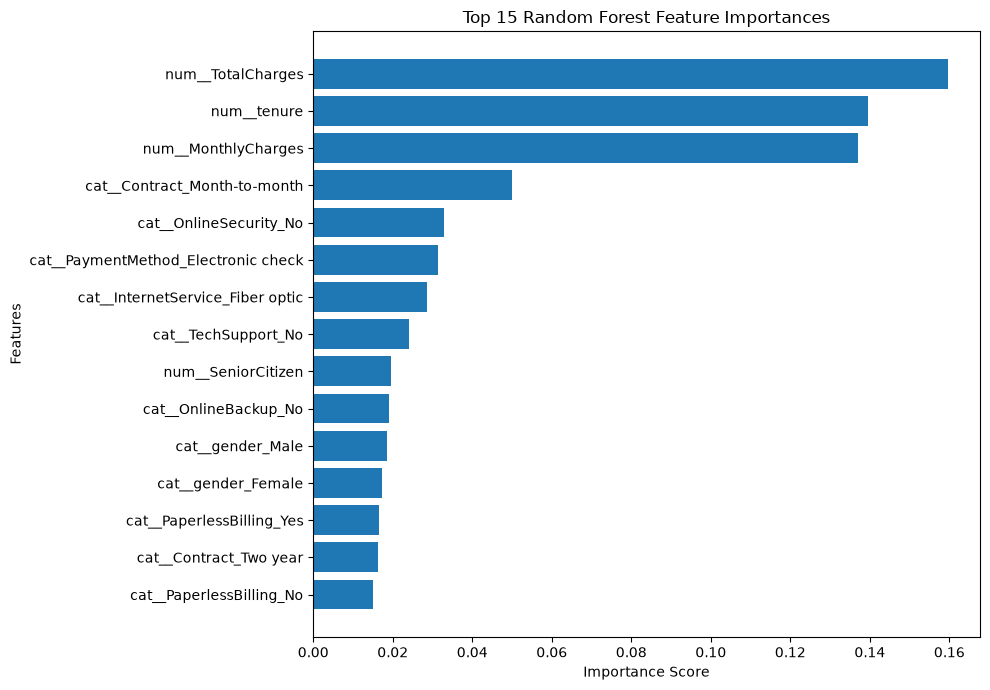

In [27]:
# Select the top 15 features
top_features = feature_importance_df.head(15)

# Sort them for a better horizontal chart
top_features = top_features.sort_values(
    by="Importance",
    ascending=True
)

# Create the chart
plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.title("Top 15 Random Forest Feature Importances")

plt.tight_layout()
plt.show()

 4.3 Feature Importance Analysis

The feature importance chart shows that TotalCharges,
tenure, and MonthlyCharges are the three most important
features for predicting customer churn.

Contract_Month-to-month is the most important categorical
feature, followed by OnlineSecurity_No and
PaymentMethod_Electronic check.

This suggests that customer payment information,
customer relationship duration, and contract details
are useful for predicting churn.

However, feature importance does not show whether a
feature increases or decreases the probability of churn.
It only measures its contribution to the model.

In [28]:
# Find incorrect predictions
wrong_predictions = np.where(rf_test_pred != y_test)[0]

print("Number of incorrect predictions:",
      len(wrong_predictions))

# Display the first incorrect prediction
first_wrong_index = wrong_predictions[0]

print("\nActual Churn:",
      y_test.iloc[first_wrong_index])

print("Predicted Churn:",
      rf_test_pred[first_wrong_index])

Number of incorrect predictions: 300

Actual Churn: 0
Predicted Churn: 1


In [29]:
# Get the customer's features
wrong_customer = X_test.iloc[first_wrong_index]

print("Customer Information:")
display(wrong_customer.to_frame(name="Value"))

print("Actual Churn:", y_test.iloc[first_wrong_index])
print("Predicted Churn:", rf_test_pred[first_wrong_index])

Customer Information:


,Value
gender,Female
SeniorCitizen,1
Partner,No
Dependents,No
tenure,8
PhoneService,Yes
MultipleLines,Yes
InternetService,Fiber optic
OnlineSecurity,No
OnlineBackup,No


Actual Churn: 0
Predicted Churn: 1


In [30]:
# Get the customer's churn probabilities
customer_probabilities = rf_model.predict_proba(
    X_test.iloc[[first_wrong_index]]
)[0]

print("Probability of No Churn:",
      round(customer_probabilities[0], 4))

print("Probability of Churn:",
      round(customer_probabilities[1], 4))

Probability of No Churn: 0.31
Probability of Churn: 0.69


In [32]:
# Transform the customer using the trained preprocessor
customer_transformed = rf_model.named_steps[
    "preprocessor"
].transform(X_test.iloc[[first_wrong_index]])

# Select the first tree
first_tree = rf_classifier.estimators_[0]

# Find the path followed by the customer
node_indicator = first_tree.decision_path(customer_transformed)
leaf_id = first_tree.apply(customer_transformed)

# Get the nodes visited by the customer
node_indices = node_indicator.indices[
    node_indicator.indptr[0]:node_indicator.indptr[1]
]

# Get transformed feature values
customer_values = customer_transformed[0]

print("Decision path through the first tree:\n")

for node_id in node_indices:
    if node_id == leaf_id[0]:
        continue

    feature_index = first_tree.tree_.feature[node_id]
    threshold = first_tree.tree_.threshold[node_id]

    feature_name = feature_names[feature_index]
    feature_value = customer_values[feature_index]

    if feature_value <= threshold:
        condition = "<="
    else:
        condition = ">"

    print(
        f"{feature_name}: {feature_value:.3f} "
        f"{condition} {threshold:.3f}"
    )

print("\nReached leaf:", leaf_id[0])

Decision path through the first tree:

cat__PaymentMethod_Electronic check: 0.000 <= 0.500
cat__TechSupport_No: 0.000 <= 0.500
cat__InternetService_Fiber optic: 1.000 > 0.500
cat__PaymentMethod_Mailed check: 0.000 <= 0.500
cat__StreamingTV_Yes: 1.000 > 0.500
num__MonthlyCharges: 100.150 <= 117.700
cat__PaymentMethod_Credit card (automatic): 1.000 > 0.500
cat__gender_Female: 1.000 > 0.500
num__TotalCharges: 908.550 <= 1951.600

Reached leaf: 551


In [33]:
print("First Tree Prediction:",
      first_tree.predict(customer_transformed)[0])

print("Random Forest Prediction:",
      rf_model.predict(X_test.iloc[[first_wrong_index]])[0])

print("Actual Churn:",
      y_test.iloc[first_wrong_index])

First Tree Prediction: 1.0
Random Forest Prediction: 1
Actual Churn: 0


 4.4 Error Analysis

The Random Forest incorrectly predicted that one customer
would churn, while the actual result was no churn.

This is a False Positive.

The model estimated a 69% probability of churn for this
customer. The customer had several characteristics
associated with churn in the dataset, such as a
month-to-month contract, short tenure, and high monthly
charges.

The decision path showed how the first tree reached its
prediction. Both the first tree and the Random Forest
predicted churn for this customer.

However, the path belongs to only one tree. The Random
Forest combines predictions from many trees, so this path
does not explain the entire forest's decision.

 4.5 Comparing Random Forest with Logistic Regression

Logistic Regression is a linear classification model.
Unlike tree-based models, it benefits from scaling
numerical features.

We will use StandardScaler for numerical features and
OneHotEncoder for categorical features.

We will also tune the regularization parameter C using
cross-validation on the training data.

In [34]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold

logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols)
    ]
)

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", logistic_preprocessor),
        ("classifier", LogisticRegression(max_iter=1000))
    ]
)

print("Logistic Regression pipeline is ready!")

Logistic Regression pipeline is ready!


 4.5 Comparing with Tuned Logistic Regression

We will tune Logistic Regression using GridSearchCV.
We will test different values of C and select the best
model based on cross-validation F1 score.

In [35]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler

logistic_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols)
    ]
)

logistic_pipeline = Pipeline(
    steps=[
        ("preprocessor", logistic_preprocessor),
        ("classifier", LogisticRegression(max_iter=2000))
    ]
)

param_grid = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    logistic_pipeline,
    param_grid,
    cv=cv,
    scoring="f1",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best C:", grid_search.best_params_)
print("Best Cross-Validation F1:", grid_search.best_score_)

Best C: {'classifier__C': 10}
Best Cross-Validation F1: 0.5975404089588198


In [36]:
best_logistic_model = grid_search.best_estimator_

logistic_train_pred = best_logistic_model.predict(X_train)
logistic_test_pred = best_logistic_model.predict(X_test)

print("Training Accuracy:",
      accuracy_score(y_train, logistic_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, logistic_test_pred))

print("Training F1 Score:",
      f1_score(y_train, logistic_train_pred))

print("Testing F1 Score:",
      f1_score(y_test, logistic_test_pred))

Training Accuracy: 0.8059992900248492
Testing Accuracy: 0.8048261178140526
Training F1 Score: 0.6012404232032105
Testing F1 Score: 0.6031746031746031


 4.6 Final Model Comparison

We compare Decision Tree, Random Forest, Gradient Boosting,
and tuned Logistic Regression using their test accuracy
and test F1 scores.

The models use the same train/test split, making this
comparison fair.

In [37]:
comparison_df = pd.DataFrame({
    "Model": [
        "Decision Tree (depth=5)",
        "Random Forest (50 trees, depth=10)",
        "Gradient Boosting",
        "Tuned Logistic Regression (C=10)"
    ],
    "Test Accuracy": [
        0.7984,
        0.8041,
        0.8027,
        0.8048
    ],
    "Test F1 Score": [
        0.5989,
        0.5929,
        0.5813,
        0.6032
    ]
})

display(comparison_df.round(4))

,Model,Test Accuracy,Test F1 Score
0,Decision Tree (depth=5),0.7984,0.5989
1,"Random Forest (50 trees, depth=10)",0.8041,0.5929
2,Gradient Boosting,0.8027,0.5813
3,Tuned Logistic Regression (C=10),0.8048,0.6032


4.7 Model Comparison Analysis

Tuned Logistic Regression achieved the best test F1 score
(0.6032) and accuracy (0.8048) among the four models.

Random Forest achieved a test accuracy of 0.8041 and
F1 score of 0.5929, while Gradient Boosting achieved
0.8027 accuracy and 0.5813 F1 score.

The Decision Tree achieved a test F1 score of 0.5989.

These results show that more complex models do not
always outperform simpler models. Logistic Regression
generalized well because its training and testing
scores were very close.

The best model depends on the evaluation metric and
the goal of the classification task.

In [39]:
best_rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=50,
            max_depth=10,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

best_rf_model.fit(X_train, y_train)

best_rf_test_pred = best_rf_model.predict(X_test)

print("Test Accuracy:",
      accuracy_score(y_test, best_rf_test_pred))

print("Test F1 Score:",
      f1_score(y_test, best_rf_test_pred))

Test Accuracy: 0.8041163946061036
Test F1 Score: 0.5929203539823009


In [40]:
# Get the trained Random Forest classifier
best_rf_classifier = best_rf_model.named_steps["classifier"]

# Get the feature names after preprocessing
best_feature_names = best_rf_model.named_steps[
    "preprocessor"
].get_feature_names_out()

# Get feature importance scores
best_importances = best_rf_classifier.feature_importances_

# Create a DataFrame
best_importance_df = pd.DataFrame({
    "Feature": best_feature_names,
    "Importance": best_importances
})

# Sort from highest to lowest
best_importance_df = best_importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(best_importance_df.head(15).round(4))

,Feature,Importance
1,num__tenure,0.1395
3,num__TotalCharges,0.1267
2,num__MonthlyCharges,0.0907
36,cat__Contract_Month-to-month,0.0900
18,cat__OnlineSecurity_No,0.0612
16,cat__InternetService_Fiber optic,0.0560
43,cat__PaymentMethod_Electronic check,0.0432
27,cat__TechSupport_No,0.0417
38,cat__Contract_Two year,0.0257
21,cat__OnlineBackup_No,0.0173


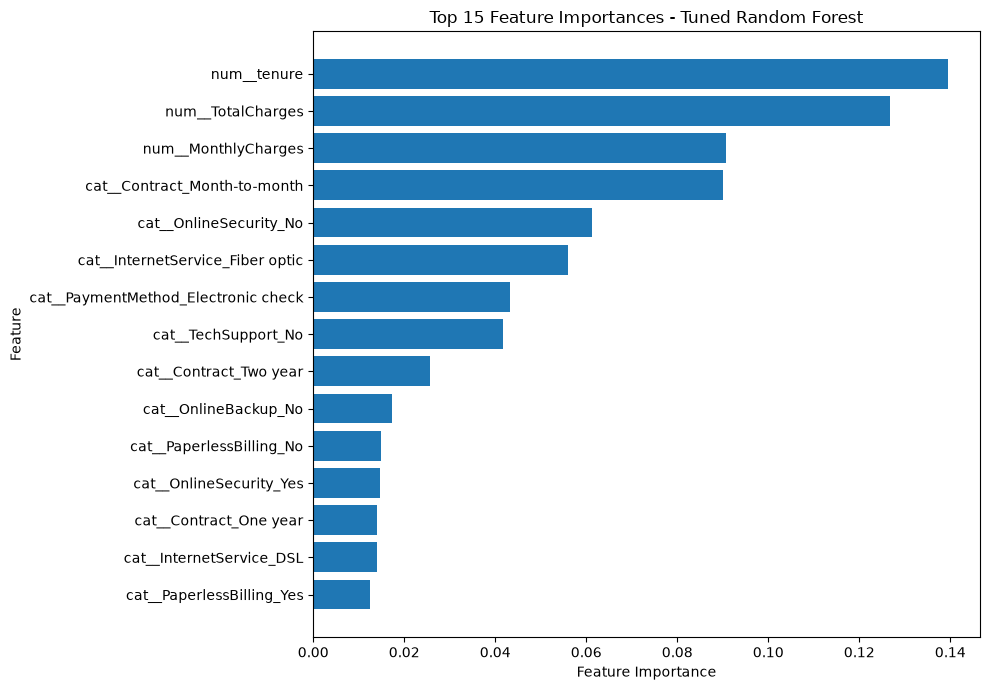

In [41]:
top_features = best_importance_df.head(15)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")
plt.title("Top 15 Feature Importances - Tuned Random Forest")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Feature Importance Analysis

The tuned Random Forest identified tenure as the most
important feature, followed by TotalCharges and
MonthlyCharges.

Contract_Month-to-month was the most important
categorical feature.

This suggests that customer duration, payment amounts,
and contract types provide useful information for
predicting customer churn.

However, feature importance does not show whether a
feature increases or decreases the probability of churn.
It only measures its contribution to the model.

In [42]:
# Find incorrect predictions
wrong_predictions = np.where(
    best_rf_test_pred != y_test
)[0]

print("Number of incorrect predictions:",
      len(wrong_predictions))

# Select the first incorrect prediction
first_wrong_index = wrong_predictions[0]

print("\nActual Churn:",
      y_test.iloc[first_wrong_index])

print("Predicted Churn:",
      best_rf_test_pred[first_wrong_index])

Number of incorrect predictions: 276

Actual Churn: 0
Predicted Churn: 1


In [43]:
wrong_customer = X_test.iloc[[first_wrong_index]]

display(wrong_customer.T)

print("Actual Churn:",
      y_test.iloc[first_wrong_index])

print("Predicted Churn:",
      best_rf_test_pred[first_wrong_index])

,2280
gender,Female
SeniorCitizen,1
Partner,No
Dependents,No
tenure,8
PhoneService,Yes
MultipleLines,Yes
InternetService,Fiber optic
OnlineSecurity,No
OnlineBackup,No


Actual Churn: 0
Predicted Churn: 1


In [44]:
customer_probabilities = best_rf_model.predict_proba(
    wrong_customer
)[0]

print("Probability of No Churn:",
      round(customer_probabilities[0], 4))

print("Probability of Churn:",
      round(customer_probabilities[1], 4))

Probability of No Churn: 0.2839
Probability of Churn: 0.7161


In [45]:
# Transform the selected customer
customer_transformed = best_rf_model.named_steps[
    "preprocessor"
].transform(wrong_customer)

# Get the first tree
first_tree = best_rf_classifier.estimators_[0]

# Get the decision path
node_indicator = first_tree.decision_path(customer_transformed)
leaf_id = first_tree.apply(customer_transformed)

node_indices = node_indicator.indices[
    node_indicator.indptr[0]:node_indicator.indptr[1]
]

customer_values = customer_transformed[0]

# Print the path
print("Decision path through the first tree:\n")

for node_id in node_indices:

    if node_id == leaf_id[0]:
        continue

    feature_index = first_tree.tree_.feature[node_id]
    threshold = first_tree.tree_.threshold[node_id]

    feature_name = best_feature_names[feature_index]
    feature_value = customer_values[feature_index]

    condition = "<=" if feature_value <= threshold else ">"

    print(
        f"{feature_name}: {feature_value:.3f} "
        f"{condition} {threshold:.3f}"
    )

print("\nReached leaf:", leaf_id[0])

Decision path through the first tree:

cat__PaymentMethod_Electronic check: 0.000 <= 0.500
cat__TechSupport_No: 0.000 <= 0.500
cat__InternetService_Fiber optic: 1.000 > 0.500
num__MonthlyCharges: 100.150 <= 117.700
num__TotalCharges: 908.550 <= 1491.800
num__MonthlyCharges: 100.150 > 80.325
num__TotalCharges: 908.550 > 131.825
cat__DeviceProtection_Yes: 0.000 <= 0.500
cat__OnlineSecurity_Yes: 0.000 <= 0.500
cat__PaymentMethod_Mailed check: 0.000 <= 0.500

Reached leaf: 173


In [46]:
print("First Tree Prediction:",
      first_tree.predict(customer_transformed)[0])

print("Random Forest Prediction:",
      best_rf_model.predict(wrong_customer)[0])

print("Actual Churn:",
      y_test.iloc[first_wrong_index])

First Tree Prediction: 1.0
Random Forest Prediction: 1
Actual Churn: 0


 Error Analysis

We inspected an incorrectly classified customer from
the test set.

The customer actually stayed with the company
(Actual Churn = 0), but the Random Forest predicted
that the customer would leave (Predicted Churn = 1).
This is a False Positive.

The model assigned a 71.61% probability to churn and
28.39% to no churn.

The customer had a short tenure of 8 months, a
month-to-month contract, and relatively high monthly
charges of $100.15.

We also inspected the decision path of the first tree
in the Random Forest. It predicted churn, which matched
the final Random Forest prediction, but both predictions
were incorrect.

This analysis shows that machine learning models can
make incorrect predictions even when they assign a
high probability to a particular class.